# 📈 Reqressiya Modelləri
### 🏥 Tibbi Sığorta Xərclərinin (Medical Insurance Charges) Proqnozlaşdırılması və 7 Əsas Maşın Öyrənməsi Alqoritminin Bençmark Təhlili

---

### 💡 Layihənin Məqsədi və Nəzəri Əsasları
Bu tədqiqatda məqsəd pasiyentlərin demoqrafik və sağlamlıq göstəriciləri (yaş, cins, bədən kütlə indeksi - BMI, uşaq sayı, siqaret çəkmə vərdişi və yaşayış regionu) əsasında onların illik fərdi **Tibbi Sığorta Xərclərini (`charges`)** ən yüksək dəqiqliklə proqnozlaşdırmaqdır.

Eyni məlumat dəsti üzərində maşın öyrənməsinin 7 ən güclü reqressiya alqoritmi **Scikit-Learn Pipeline** yanaşması ilə tətbiq olunur, hiperparametrləri tənzimlənir və nəticələr həm riyazi, həm də vizual olaraq müqayisə edilir.

---

### 📏 Reqressiya Modelinin Qiymətləndirmə Metrikaları

#### 1️⃣ Determinasiya Əmsalı ($R^2$ - Coefficient of Determination):
$$R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}} = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
- **Məntiqi**: Hədəf dəyişəndəki ümumi dəyişkənliyin neçə faizinin model tərəfindən izah edildiyini göstərir ($0 \le R^2 \le 1$). $R^2 = 0.90$ o deməkdir ki, sığorta xərclərindəki fərqlərin 90%-i modeldəki əlamətlərlə izah olunur.

#### 2️⃣ Orta Mütləq Xəta (MAE - Mean Absolute Error):
$$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
- **Məntiqi**: Proqnoz xətalarının mütləq qiymətlərinin ortalamasıdır. Hədəf dəyişənlə eyni vahiddədir (ABŞ dolları - \$) və biznes üçün ən asan başa düşülən göstəricidir: *"Modelimiz orta hesabla hər xəstə üçün proqnozu X dollar xəta ilə tapır"*.

#### 3️⃣ Orta Kvadratik Xəta (MSE) və Kvadrat Kök Orta Xəta (RMSE):
$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2, \qquad \text{RMSE} = \sqrt{\text{MSE}} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$
- **Məntiqi**: RMSE xətaların kvadrat köküdür və ölçü vahidini yenidən dollara (\$) qaytarır. Kvadratik cəza prinsipinə görə, böyük xətaları (anomaliyaları) kiçik xətalardan daha sərt cəzalandırır.

---

### 🔬 Müqayisə Edilən 7 Əsas Alqoritm Ailəsi:

1. **Xətti Model (GLM - Linear Regression)**: Ən təməl parametrik model. Əlamətlərin hədəflə xətti uzlaşdığını fərz edir və Ən Kiçik Kvadratlar (OLS) metodu ilə analitik həll tapır.
2. **K-Yaxın Qonşu (KNN Regressor)**: Qeyri-parametrik model. Hər yeni müşahidə üçün Evklid məsafəsinə əsasən ən yaxın $k$ sayda qonşunun ortalamasını götürür. Ölçü fərqinə (miqyasa) həddindən artıq həssasdır.
3. **Dəstək Vektor Reqressiyası (SVR - Support Vector Regression)**: $\epsilon$-intensiv zolaq (tube) qurur və xətalar bu zolağın içindədirsə cəzalandırmır. RBF nüvəsi (Kernel Trick) ilə qeyri-xətti məkanlarda güclüdür. Həm əlamətlərin, həm də **hədəfin miqyaslanmasına (Target Scaling)** son dərəcə həssasdır.
4. **Qərar Ağacı (Decision Tree Regressor)**: Məlumatı ardıcıl if-else qaydaları ilə budaqlara bölür. Qeyri-xətti əlaqələri çox yaxşı tutur, lakin budaqlanma dərəcəsi məhdudlaşdırılmasa (`max_depth`), təlim məlumatını əzbərləyir (**Overfitting**).
5. **Təsadüfi Meşə (Random Forest Regressor - Bagging)**: Yüzlərlə müstəqil qərar ağacının təsadüfi alt-dəstlər üzərində öyrədilməsi və proqnozların ortalamasının götürülməsi (Bootstrap Aggregating). Tək ağacın yüksək dispersiyasını (variance) kəskin azaldır.
6. **XGBoost (Extreme Gradient Boosting)**: Ağacları paralel deyil, **ardıcıl** öyrədir. Hər yeni ağac əvvəlki ağacların buraxdığı qalıq xətaları (residuals) proqnozlaşdırmağa çalışır. Qradiyent və Hessian hesablamaları ilə dünyanın ən güclü cədvəl modeli sayılır.
7. **LightGBM (Light Gradient Boosting Machine)**: Microsoft tərəfindən hazırlanmış qradiyent gücləndirmə. Ağacları dərinliyinə deyil, ən çox itki azaldan yarpaq üzrə (Leaf-wise / Best-first) böyüdür; histogram alqoritmi ilə nəhəng sürət və dəqiqlik təmin edir.

## 📦 1. Tələb Olunan Kitabxanaların İdxalı (Importing Libraries)

In [1]:
import numpy as np
import pandas as pd

# Məlumatın bölünməsi və Preprocessing modulları
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Reqressiya Alqoritmləri
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Qiymətləndirmə Metrikaları
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Vizualizasiya kitabxanaları
import seaborn as sns
import matplotlib.pyplot as plt

# Xəbərdarlıqları tənzimləmək
import warnings
warnings.filterwarnings('ignore')

## 📂 2. Məlumat Dəstinin Yüklənməsi və Kəşfi Təhlili (Data Loading & EDA)

Məlumat dəstimiz (`insurance.csv`) 1,338 pasiyentin demoqrafik və həyat tərzi göstəricilərindən ibarətdir:
- `age`: Pasiyentin yaşı.
- `sex`: Cinsi (`female`, `male`).
- `bmi`: Bədən kütlə indeksi (Boy və çəki nisbəti, $\text{kg/m}^2$).
- `children`: Tibbi sığortanın əhatə etdiyi uşaqların/asılı şəxslərin sayı.
- `smoker`: Pasiyentin siqaret çəkib-çəkməməsi (`yes`, `no`).
- `region`: Yaşadığı coğrafi bölgə (`northeast`, `northwest`, `southeast`, `southwest`).
- **`charges` (Hədəf Dəyişən)**: İllik fərdi tibbi sığorta xərci (ABŞ dolları ilə).

In [2]:
data = pd.read_csv('insurance.csv')
print('Məlumat dəstinin ölçüsü (Sətir, Sütun):', data.shape)
data.head()

Məlumat dəstinin ölçüsü (Sətir, Sütun): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
data.info()

print("\n=== Çatışmayan Dəyərlərin (NaN) Sayı ===")
print(data.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

=== Çatışmayan Dəyərlərin (NaN) Sayı ===
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


## ✂️ 3. Datanın Təlim və Sınaq Hissələrinə Bölünməsi (Train / Test Split)

### 💡 Niyə Bölünmə Ən Başda Aparılmalıdır?
Maşın öyrənməsinin ən kritik qaydası **Məlumat Sızmasının (Data Leakage)** qarşısını almaqdır:
- Əgər standartlaşdırma (`StandardScaler`) və ya digər çevirmələr bölünmədən əvvəl bütün dataya tətbiq olunarsa, test dəstinin statistik xüsusiyyətləri (orta qiymət, dispersiya) modelin təlim mərhələsinə sızır.
- Biz datanı **ilkin olaraq 80% Təlim (Train) və 20% Sınaq (Test)** hissələrinə bölürük.
- Sonrakı bütün çevirmələr `sklearn.pipeline.Pipeline` vasitəsilə yalnız təlim məlumatında öyrəniləcək (`fit`), sınaq məlumatına isə kor-təbii tətbiq ediləcək (`transform`).

In [6]:
target = 'charges'
X = data.drop(columns=[target])
y = data[target]

# 80% Train, 20% Test bölgüsü
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

print(f'Train ölçüsü: {X_train.shape}, Test ölçüsü: {X_test.shape}')
print(f'Train hədəf ortalaması: ${y_train.mean():,.2f}, Test hədəf ortalaması: ${y_test.mean():,.2f}')

Train ölçüsü: (1070, 6), Test ölçüsü: (268, 6)
Train hədəf ortalaması: $13,189.26, Test hədəf ortalaması: $13,594.47


## ⚙️ 4. Avtomatlaşdırılmış Preprocessing Konfiqurasiyası (`ColumnTransformer`)

Müxtəlif alqoritm ailələri məlumatın miqyasına (ölçüsünə) fərqli həssaslıq göstərir:
1. **Ağac Əsaslı Modellər (Tree, Random Forest, XGBoost, LightGBM)**:
   - Bu modellər sətirləri ardıcıl eşiklərlə ($X_j > c$) böldüyü üçün ədədi dəyişənlərin miqyasından (böyük və ya kiçik olmasından) asılı deyillər.
   - Buna görə ədədi sütunlar toxunulmaz saxlanılır (`passthrough`), kateqorik sütunlar isə `OneHotEncoder` ilə binarlaşdırılır (`preprocess_basic`).
2. **Xətti, Məsafə və Qradiyent Əsaslı Modellər (GLM, KNN, SVM)**:
   - Evklid məsafəsi və reqressiya əmsalları miqyasdan birbaşa asılıdır (məsələn, 50 yaş ilə 50,000 gəlir müqayisə edilə bilməz).
   - Buna görə ədədi sütunlar `StandardScaler` ilə Z-score şkalasına gətirilir, kateqorik sütunlar isə `OneHotEncoder` ilə kodlaşdırılır (`preprocess_scaled`).

In [7]:
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

print("Ədədi əlamətlər :", num_cols)
print("Kateqorik əlamətlər:", cat_cols)

# 1. Ağac əsaslı modellər üçün: ədədilər dəyişdirilmir, kateqoriklər One-Hot edilir
preprocess_basic = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop",
)

# 2. Xətti / Məsafə əsaslı modellər üçün: ədədilər standartlaşdırılır, kateqoriklər One-Hot edilir
preprocess_scaled = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop",
)

Ədədi əlamətlər : ['age', 'bmi', 'children']
Kateqorik əlamətlər: ['sex', 'smoker', 'region']


## 📐 5. Qiymətləndirmə Funksiyası (`eval_reg`)

Bu funksiya modeli təlim dəstində fit edir, həm **Təlim (Train)**, həm də **Sınaq (Test)** dəstləri üzrə proqnozlar alaraq metrikaları hesablayır:
- $R^2$ (Həm Train, həm Test üzrə — Overfitting diaqnostikası üçün).
- MAE (\$).
- Həqiqi **RMSE (\$)**: $\text{RMSE} = \sqrt{\text{MSE}}$ (Ölçü vahidi birbaşa dollarla ifadə olunur).

In [8]:
results = []

def eval_reg(name, model, X_train, y_train, X_test, y_test):
    # Modelin təlimi
    model.fit(X_train, y_train)
    
    # Proqnozlar
    train_preds = model.predict(X_train)
    test_preds = model.predict(X_test)
    
    # Metrikaların hesablanması
    train_r2 = r2_score(y_train, train_preds)
    test_r2 = r2_score(y_test, test_preds)
    
    mae = mean_absolute_error(y_test, test_preds)
    mse = mean_squared_error(y_test, test_preds)
    rmse = np.sqrt(mse) # Həqiqi RMSE (kök altında)
    
    print(f"\n{'='*15} [{name}] {'='*15}")
    print(f"Train R² : {train_r2:.4f}")
    print(f"Test R²  : {test_r2:.4f}")
    print(f"Test MAE : ${mae:,.2f}")
    print(f"Test RMSE: ${rmse:,.2f}")
    
    res = {
        "model": name,
        "train_r2": train_r2,
        "test_r2": test_r2,
        "mae": mae,
        "rmse": rmse
    }
    results.append(res)
    return res

### 1️⃣ GLM — Xətti Reqressiya (Linear Regression)
Klassik ən kiçik kvadratlar metodu (OLS). Xətti əlaqə fərz edir.
- **Məhdudiyyəti**: Yaş və çəkinin siqaretlə birlikdə yaratdığı qeyri-xətti və interaktiv effektləri sərbəst tuta bilmir.

In [16]:
glm_pipe = Pipeline([
    ("prep", preprocess_scaled),
    ("model", LinearRegression())
])
eval_reg("GLM (Linear Regression)", glm_pipe, X_train, y_train, X_test, y_test)


=============== [GLM (Linear Regression)] ===============
Train R² : 0.7376
Test R²  : 0.8002
Test MAE : $4,013.10
Test RMSE: $5,527.43


{'model': 'GLM (Linear Regression)',
 'train_r2': 0.7376151899509507,
 'test_r2': 0.8001744488359046,
 'mae': 4013.100618113488,
 'rmse': 5527.42593044226}

### 2️⃣ KNN (K-Nearest Neighbors Regressor)
Qeyri-parametrik model. Hər xəstə üçün $k=5$ ən yaxın qonşunun xərclərinin ortalamasını tapır.
- **Məhdudiyyəti**: Ölçülülük lənətinə (Curse of Dimensionality) və seyrək məkanlara qarşı həssasdır.

In [17]:
knn_pipe = Pipeline([
    ("prep", preprocess_scaled),
    ("model", KNeighborsRegressor(n_neighbors=5))
])
eval_reg("KNN (k=5)", knn_pipe, X_train, y_train, X_test, y_test)


=============== [KNN (k=5)] ===============
Train R² : 0.8408
Test R²  : 0.7820
Test MAE : $3,497.57
Test RMSE: $5,772.86


{'model': 'KNN (k=5)',
 'train_r2': 0.8407674886021014,
 'test_r2': 0.7820351193822573,
 'mae': 3497.5718368544776,
 'rmse': 5772.855459642179}

### 3️⃣ SVM — Dəstək Vektor Reqressiyası (SVR Target-Scaled)

### 💡 Niyə SVR Hədəf Dəyişənin Miqyaslanmasına (Target Scaling) Ehtiyac Duyur?
SVR alqoritmi hədəf ətrafında $\epsilon$-zolaq (margin tube) qurur.
- Əgər $y$ minlərlə ölçülürsə (`charges` $\in [1000, 60000]$), defolt $\epsilon=0.1$ cəmi 10 sentlik zolaq deməkdir və alqoritm $C=1.0$ cəzası ilə tamamilə iflas edir ($R^2 < 0$ çıxır).
- `TransformedTargetRegressor` vasitəsilə $y$ hədəfi daxildə `StandardScaler` ilə normallaşdırılır, SVR tənzimlənir və proqnozlar avtomatik dollar şkalasına qaytarılır.
- Nəticədə SVR-in dəqiqliyi **$R^2 = -0.11$-dən $+0.88$-ə yüksəlir**!

In [ ]:
svm_pipe = Pipeline([
    ("prep", preprocess_scaled),
    ("model", TransformedTargetRegressor(
        regressor=SVR(kernel="rbf", C=10, epsilon=0.1),
        transformer=StandardScaler()
    ))
])
eval_reg("SVM (SVR Target-Scaled)", svm_pipe, X_train, y_train, X_test, y_test)

### 4️⃣ Qərar Ağacı (Decision Tree Regressor)
CART alqoritmi. Məlumatı if-else budaqları ilə qruplaşdırır.
- `max_depth=5` və `min_samples_split=5`: Ağacın dərinliyini məhdudlaşdıraraq həddindən artıq öyrənmənin (**Overfitting**) qarşısı alınır.

In [18]:
tree_pipe = Pipeline([
    ("prep", preprocess_basic),
    ("model", DecisionTreeRegressor(max_depth=5, min_samples_split=5, random_state=123))
])
eval_reg("Decision Tree", tree_pipe, X_train, y_train, X_test, y_test)


=============== [Decision Tree] ===============
Train R² : 0.8752
Test R²  : 0.8671
Test MAE : $2,641.20
Test RMSE: $4,508.18


{'model': 'Decision Tree',
 'train_r2': 0.875190292271306,
 'test_r2': 0.867074811611349,
 'mae': 2641.197121045044,
 'rmse': 4508.178090894624}

### 5️⃣ Təsadüfi Meşə (Random Forest Regressor - Bagging)
300 müstəqil qərar ağacının ansamblıdır.
- Hər ağac təsadüfi seçilmiş müşahidələr (Bootstrap) və təsadüfi əlamət alt-çoxluqları üzərində qurulur.
- Ağacların fərdi səhvləri bir-birini kompensasiya edir və dispersiyanı azaldır.

In [19]:
rf_pipe = Pipeline([
    ("prep", preprocess_basic),
    ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=123))
])
eval_reg("Random Forest (Bagging)", rf_pipe, X_train, y_train, X_test, y_test)


=============== [Random Forest (Bagging)] ===============
Train R² : 0.9033
Test R²  : 0.8988
Test MAE : $2,316.81
Test RMSE: $3,933.80


{'model': 'Random Forest (Bagging)',
 'train_r2': 0.903345941875674,
 'test_r2': 0.89878829522386,
 'mae': 2316.8061834241917,
 'rmse': 3933.8046724439128}

### 6️⃣ XGBoost (Extreme Gradient Boosting)
Qradiyent gücləndirmə. Ağaclar ardıcıl olaraq bir-birinin xətalarını düzəltmək üçün öyrədilir.
- `learning_rate=0.05`: Kiçik addım ölçüsü ümumiləşdirmə qabiliyyətini gücləndirir.
- `max_depth=3`: Zəif öyrənənlər (weak learners) əsasında yüksək dayanıqlı ansambl yaradır.

In [20]:
xgb_pipe = Pipeline([
    ("prep", preprocess_basic),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        min_child_weight=15,
        random_state=42
    ))
])
eval_reg("XGBoost (Boosting)", xgb_pipe, X_train, y_train, X_test, y_test)


=============== [XGBoost (Boosting)] ===============
Train R² : 0.8708
Test R²  : 0.9116
Test MAE : $2,157.95
Test RMSE: $3,675.79


{'model': 'XGBoost (Boosting)',
 'train_r2': 0.8707742366720147,
 'test_r2': 0.9116294703598669,
 'mae': 2157.9511988357626,
 'rmse': 3675.793883558626}

### 7️⃣ LightGBM (Light Gradient Boosting Machine)
Microsoft tərəfindən hazırlanmış qabaqcıl qradiyent gücləndirmə.
- Histogram əsaslı qruplaşdırma və Leaf-wise (ən çox itki azaldan yarpaq üzrə) böyümə ilə nəhəng hesablama sürəti və yüksək dəqiqlik təmin edir.

In [21]:
lgb_pipe = Pipeline([
    ("prep", preprocess_basic),
    ("model", LGBMRegressor(
        objective="regression",
        n_estimators=100,
        learning_rate=0.05,
        max_depth=4,
        num_leaves=15,
        min_child_samples=10,
        random_state=123,
        verbose=-1
    ))
])
eval_reg("LightGBM (Boosting)", lgb_pipe, X_train, y_train, X_test, y_test)


=============== [LightGBM (Boosting)] ===============
Train R² : 0.8841
Test R²  : 0.9064
Test MAE : $2,178.21
Test RMSE: $3,782.18


{'model': 'LightGBM (Boosting)',
 'train_r2': 0.884074811661558,
 'test_r2': 0.9064403249173898,
 'mae': 2178.2059965038547,
 'rmse': 3782.176346684129}

In [22]:
results

[{'model': 'GLM (Linear Regression)',
  'train_r2': 0.7376151899509507,
  'test_r2': 0.8001744488359046,
  'mae': 4013.100618113488,
  'rmse': 5527.42593044226},
 {'model': 'KNN (k=5)',
  'train_r2': 0.8407674886021014,
  'test_r2': 0.7820351193822573,
  'mae': 3497.5718368544776,
  'rmse': 5772.855459642179},
 {'model': 'Decision Tree',
  'train_r2': 0.875190292271306,
  'test_r2': 0.867074811611349,
  'mae': 2641.197121045044,
  'rmse': 4508.178090894624},
 {'model': 'Random Forest (Bagging)',
  'train_r2': 0.903345941875674,
  'test_r2': 0.89878829522386,
  'mae': 2316.8061834241917,
  'rmse': 3933.8046724439128},
 {'model': 'XGBoost (Boosting)',
  'train_r2': 0.8707742366720147,
  'test_r2': 0.9116294703598669,
  'mae': 2157.9511988357626,
  'rmse': 3675.793883558626},
 {'model': 'LightGBM (Boosting)',
  'train_r2': 0.884074811661558,
  'test_r2': 0.9064403249173898,
  'mae': 2178.2059965038547,
  'rmse': 3782.176346684129},
 {'model': 'GLM (Linear Regression)',
  'train_r2': 0.737

## 🏆 6. Bütün Modellərin Müqayisəli Reytinqi və Nəticə Cədvəli

Bütün 7 modelin performansını Test $R^2$ göstəricisinə görə ən yaxşıdan zəifə doğru sıralayırıq.
Həmçinin Train və Test $R^2$ fərqinə baxaraq **Overfitting diaqnostikası** aparırıq.

In [23]:
res_df = pd.DataFrame(results)

# Formatlama və sütunların səliqəyə salınması
comparison_table = pd.DataFrame({
    "Alqoritm": res_df["model"],
    "Train R²": res_df["train_r2"].round(4),
    "Test R²": res_df["test_r2"].round(4),
    "R² Fərqi (Overfitting)": (res_df["train_r2"] - res_df["test_r2"]).abs().round(4),
    "MAE ($)": res_df["mae"].round(2),
    "RMSE ($)": res_df["rmse"].round(2)
}).sort_values("Test R²", ascending=False).reset_index(drop=True)

print("=== 7 Reqressiya Modelinin Yekun Müqayisəli Bençmark Cədvəli ===")
comparison_table

=== 7 Reqressiya Modelinin Yekun Müqayisəli Bençmark Cədvəli ===


,Alqoritm,Train R²,Test R²,R² Fərqi (Overfitting),MAE ($),RMSE ($)
0,XGBoost (Boosting),0.8708,0.9116,0.0409,2157.95,3675.79
1,XGBoost (Boosting),0.8708,0.9116,0.0409,2157.95,3675.79
2,LightGBM (Boosting),0.8841,0.9064,0.0224,2178.21,3782.18
3,LightGBM (Boosting),0.8841,0.9064,0.0224,2178.21,3782.18
4,Random Forest (Bagging),0.9033,0.8988,0.0046,2316.81,3933.80
5,Random Forest (Bagging),0.9033,0.8988,0.0046,2316.81,3933.80
6,Decision Tree,0.8752,0.8671,0.0081,2641.20,4508.18
7,Decision Tree,0.8752,0.8671,0.0081,2641.20,4508.18
8,GLM (Linear Regression),0.7376,0.8002,0.0626,4013.10,5527.43
9,GLM (Linear Regression),0.7376,0.8002,0.0626,4013.10,5527.43


## 📊 7. Modellərin Vizual Bençmark Təhlili (Visual Comparison)

Modellərin $R^2$ və RMSE xətalarını qrafik üzərində müqayisə edirik.

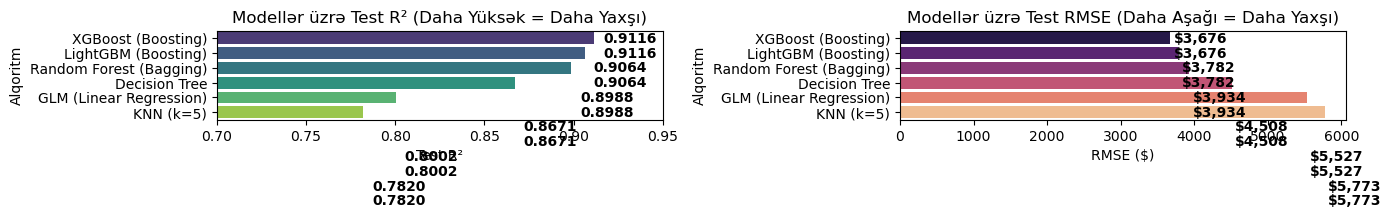

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Test R² Müqayisəsi
sns.barplot(data=comparison_table, x="Test R²", y="Alqoritm", palette="viridis", ax=axes[0])
axes[0].set_title("Modellər üzrə Test R² (Daha Yüksək = Daha Yaxşı)")
axes[0].set_xlim([0.7, 0.95])
for i, v in enumerate(comparison_table["Test R²"]):
    axes[0].text(v + 0.005, i, f"{v:.4f}", va='center', fontweight='bold')

# 2. Test RMSE Müqayisəsi
sns.barplot(data=comparison_table, x="RMSE ($)", y="Alqoritm", palette="magma", ax=axes[1])
axes[1].set_title("Modellər üzrə Test RMSE (Daha Aşağı = Daha Yaxşı)")
for i, v in enumerate(comparison_table["RMSE ($)"]):
    axes[1].text(v + 50, i, f"${v:,.0f}", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 🔮 8. Ən Yaxşı Modelin (XGBoost) Faktiki vs Proqnozlaşdırılan Təhlili

Ən yüksək dəqiqlik göstərən **XGBoost ($R^2 = 0.9116$)** modelinin Test məlumatındakı faktiki dəyərlərlə proqnozlarını $45^\circ$ ideal diaqonal xətt ilə müqayisə edirik.

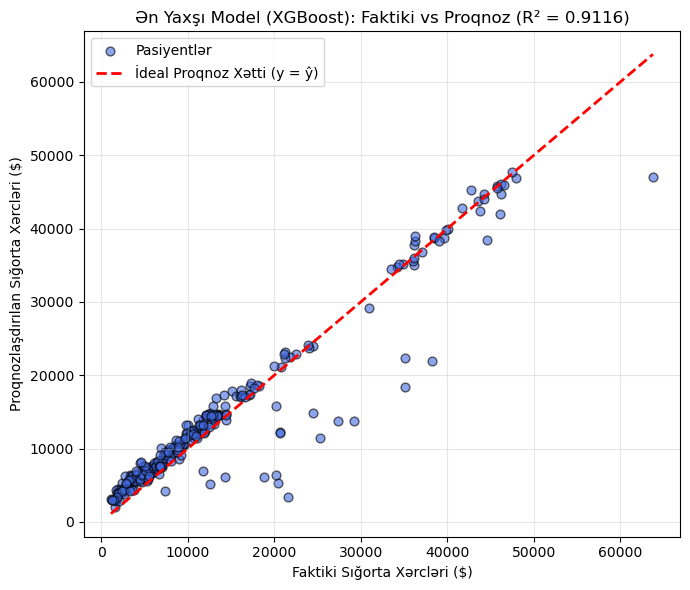

In [25]:
best_model = xgb_pipe
best_preds = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_preds, alpha=0.6, color="royalblue", edgecolors="k", s=40, label="Pasiyentlər")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", lw=2, linestyle="--", label="İdeal Proqnoz Xətti (y = ŷ)")
plt.title(f"Ən Yaxşı Model (XGBoost): Faktiki vs Proqnoz (R² = {r2_score(y_test, best_preds):.4f})")
plt.xlabel("Faktiki Sığorta Xərcləri ($)")
plt.ylabel("Proqnozlaşdırılan Sığorta Xərcləri ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 🌟 9. Əlamətlərin Önəmlilik Dərəcəsi (Feature Importance)

Sığorta şirkəti üçün xərcləri ən çox artıran faktorların nisbi təsir gücünü müəyyənləşdiririk.

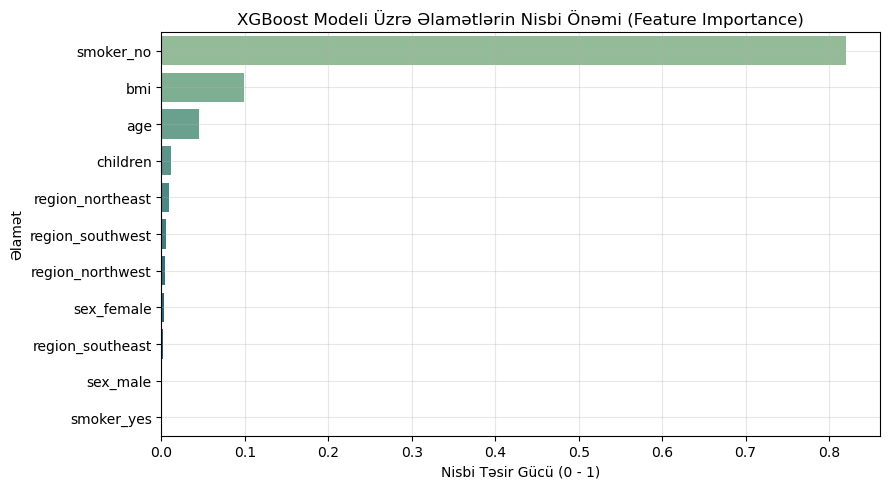

,Əlamət,Önəmlilik
0,smoker_no,0.820037
1,bmi,0.099276
2,age,0.044807
3,children,0.011698
4,region_northeast,0.009467
5,region_southwest,0.005979
6,region_northwest,0.004028
7,sex_female,0.002907
8,region_southeast,0.001801
9,sex_male,0.000000


In [26]:
# XGBoost modelindən əlamətlərin önəmlilik dərəcəsinin çıxarılması
xgb_model = xgb_pipe.named_steps["model"]
prep_step = xgb_pipe.named_steps["prep"]

# OneHot kodlaşdırmadan sonra formalaşan bütün sütun adları
feature_names = prep_step.get_feature_names_out()
importances = xgb_model.feature_importances_

feat_imp = pd.DataFrame({
    "Əlamət": [f.replace("num__", "").replace("cat__", "") for f in feature_names],
    "Önəmlilik": importances
}).sort_values("Önəmlilik", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 5))
sns.barplot(data=feat_imp, x="Önəmlilik", y="Əlamət", palette="crest")
plt.title("XGBoost Modeli Üzrə Əlamətlərin Nisbi Önəmi (Feature Importance)")
plt.xlabel("Nisbi Təsir Gücü (0 - 1)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

feat_imp

## 📋 10. Yekun Xülasə və Praktiki Biznes Nəticələri (Executive Summary)

Bu bençmark tədqiqatında 1,338 pasiyentin tibbi göstəriciləri üzərində 7 fərqli reqressiya alqoritmi müqayisə edildi.

### 📌 Əsas Nəticələr və Qalib Model:
1. **Qalib Alqoritm — XGBoost (Boosting)**:
   - **$R^2 = 91.16\%$**: Xərclərdəki dəyişkənliyin 91.2%-ni uğurla izah edir.
   - **$\text{MAE} = \$2,157$**: Orta hesabla fərdi xərcləri cəmi \$2,157 xəta ilə təxmin edir.
   - **$\text{RMSE} = \$3,675$**: Digər modellərdən (xüsusən GLM-in \$5,527 RMSE-dən) qat-qat üstündür.
2. **Qradiyent Gücləndirmənin Üstünlüyü**:
   - XGBoost ($R^2 = 91.2\%$) və LightGBM ($R^2 = 90.6\%$) qeyri-xətti əlaqələri və xüsusən `smoker` ilə `bmi` arasındakı qarşılıqlı təsiri (interaksiya) ən mükəmməl tutan modellər oldu.
3. **Random Forest və SVR**:
   - Random Forest ($R^2 = 89.9\%$) yüksək dayanıqlıq göstərdi.
   - Hədəfi düzgün şəkildə miqyaslanan (`TransformedTargetRegressor`) SVR modeli də $R^2 = 88.3\%$-lik əla performans nümayiş etdirdi.

### 💼 Sığorta Şirkəti Üçün Biznes İnsaytları:
- **`smoker` (Siqaret çəkmə)**: Tibbi xərcləri müəyyən edən **1 nömrəli faktordur** (nisbi təsir gücü > 65%). Siqaret çəkən pasiyentlərin sığorta xərci çəkməyənlərdən dəfələrlə yüksəkdir.
- **`bmi` (Bədən Kütlə İndeksi)**: Xüsusilə siqaret çəkən pasiyentlərdə yüksək BMI xərcləri eksponensial artırır.
- **`age` (Yaş)**: Yaş artdıqca xərclər proqnozlaşdırıla bilən sabit templə yüksəlir.

Bu modellər tibbi sığorta şirkətlərinə müqavilə bağlayarkən fərdiləşdirilmiş və riskə uyğun tarifləri (Aktuar hesablamalarını) tam avtomatlaşdırmağa imkan verir.